# COU 07506 Digital Signal Processing
## Week 1 — Lab 0: Setting Up the DSP Laboratory

| | |
|---|---|
| **Name** | MAIMUNA SHABANI HAJI |
| **Registration number** | 250242423358 |
| **Date** | 25 November 2026 |
| **Group** | 30 |
| **Lecturer** | Dr. Haji Fimbombaya |

**Group 30 members**

1. PAUL MASHAKA NYANDA
2. MAIMUNA SHABANI HAJI
3. ABDULKARIM MAKIWA SAID
4. SYLIVESTER M. MAGUHWA
5. ABRON JAMES MPIRA

## Pre-lab preparation
1. Read *How to Use This Handout* and §1.1 of the handout. ✔
2. DIT-eLMS login and Google account / local Python checked. ✔
3. **Three devices I used today that contain DSP, and one signal each processes:**

| Device | Signal it processes | DSP that is done on it |
|---|---|---|
| Smartphone | my voice from the microphone during a call | noise suppression, echo cancellation and speech compression before transmission |
| Wireless earphones / Bluetooth speaker | digital audio stream | decoding the compressed audio, equalisation, volume control |
| TV decoder (e.g. Azam TV / DStv) | received digital TV signal | demodulation, error correction and video/audio decompression |

## Standard imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 1.1 — Your first notebook
Elementary sequences for $-5 \le n \le 10$: unit impulse, unit step, unit ramp and real exponential.

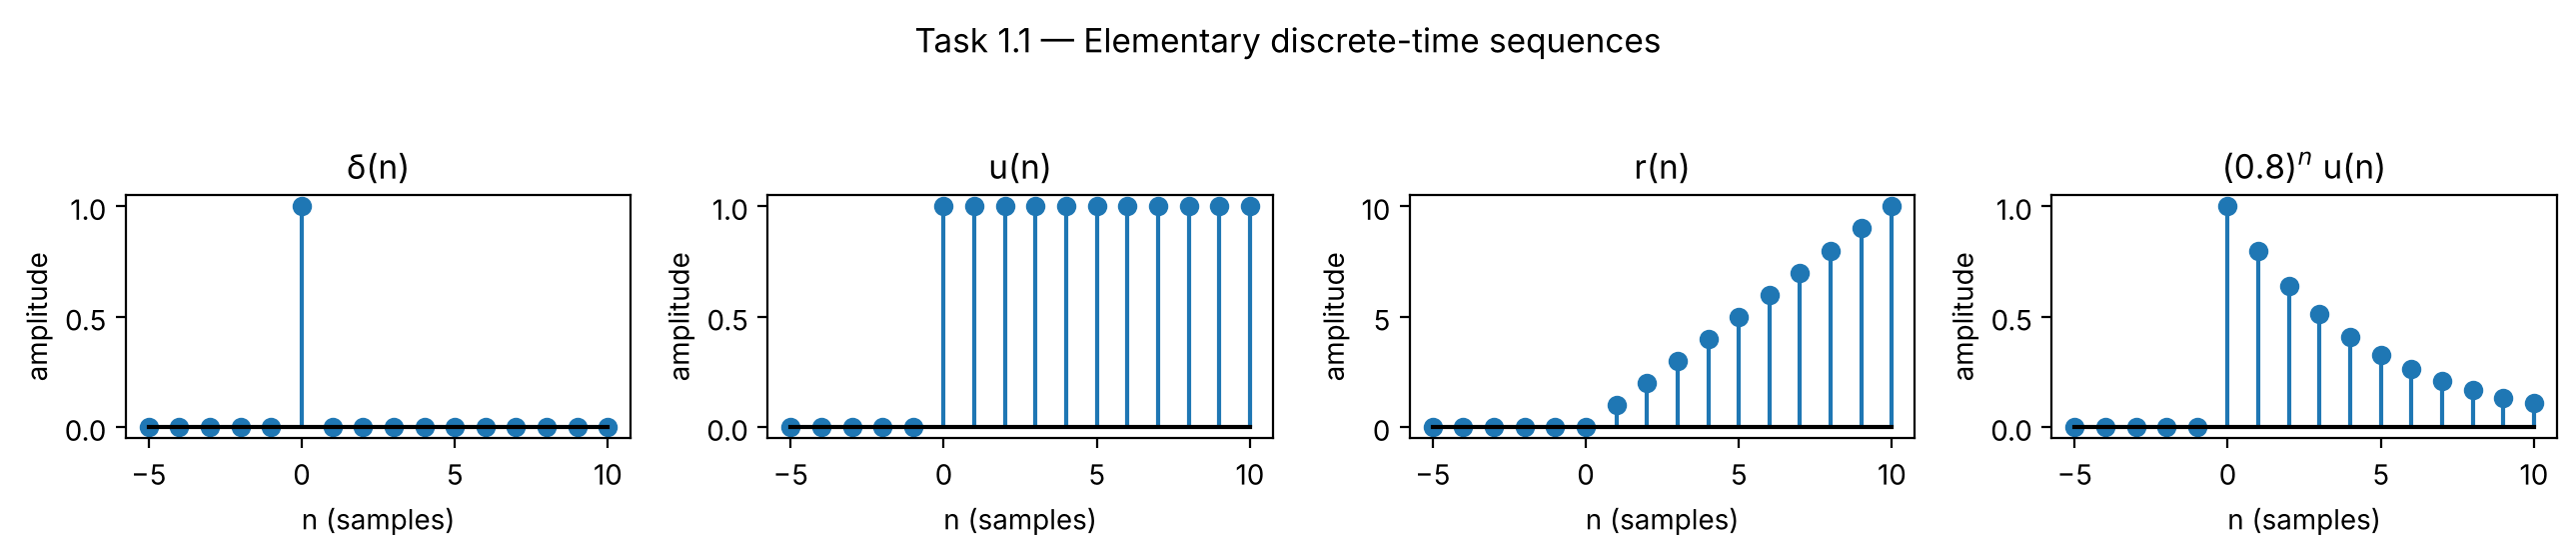

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)          # unit impulse
step = (n >= 0).astype(float)           # unit step
ramp = n * step                         # unit ramp
expo = 0.8**n * step                    # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)$^n$ u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
fig.suptitle("Task 1.1 — Elementary discrete-time sequences", y=1.05)
plt.tight_layout(); plt.show()

## Task 1.2 — Change the parameters
### 1. $a^n u(n)$ for $a = 0.5,\ -0.8,\ 1.1$

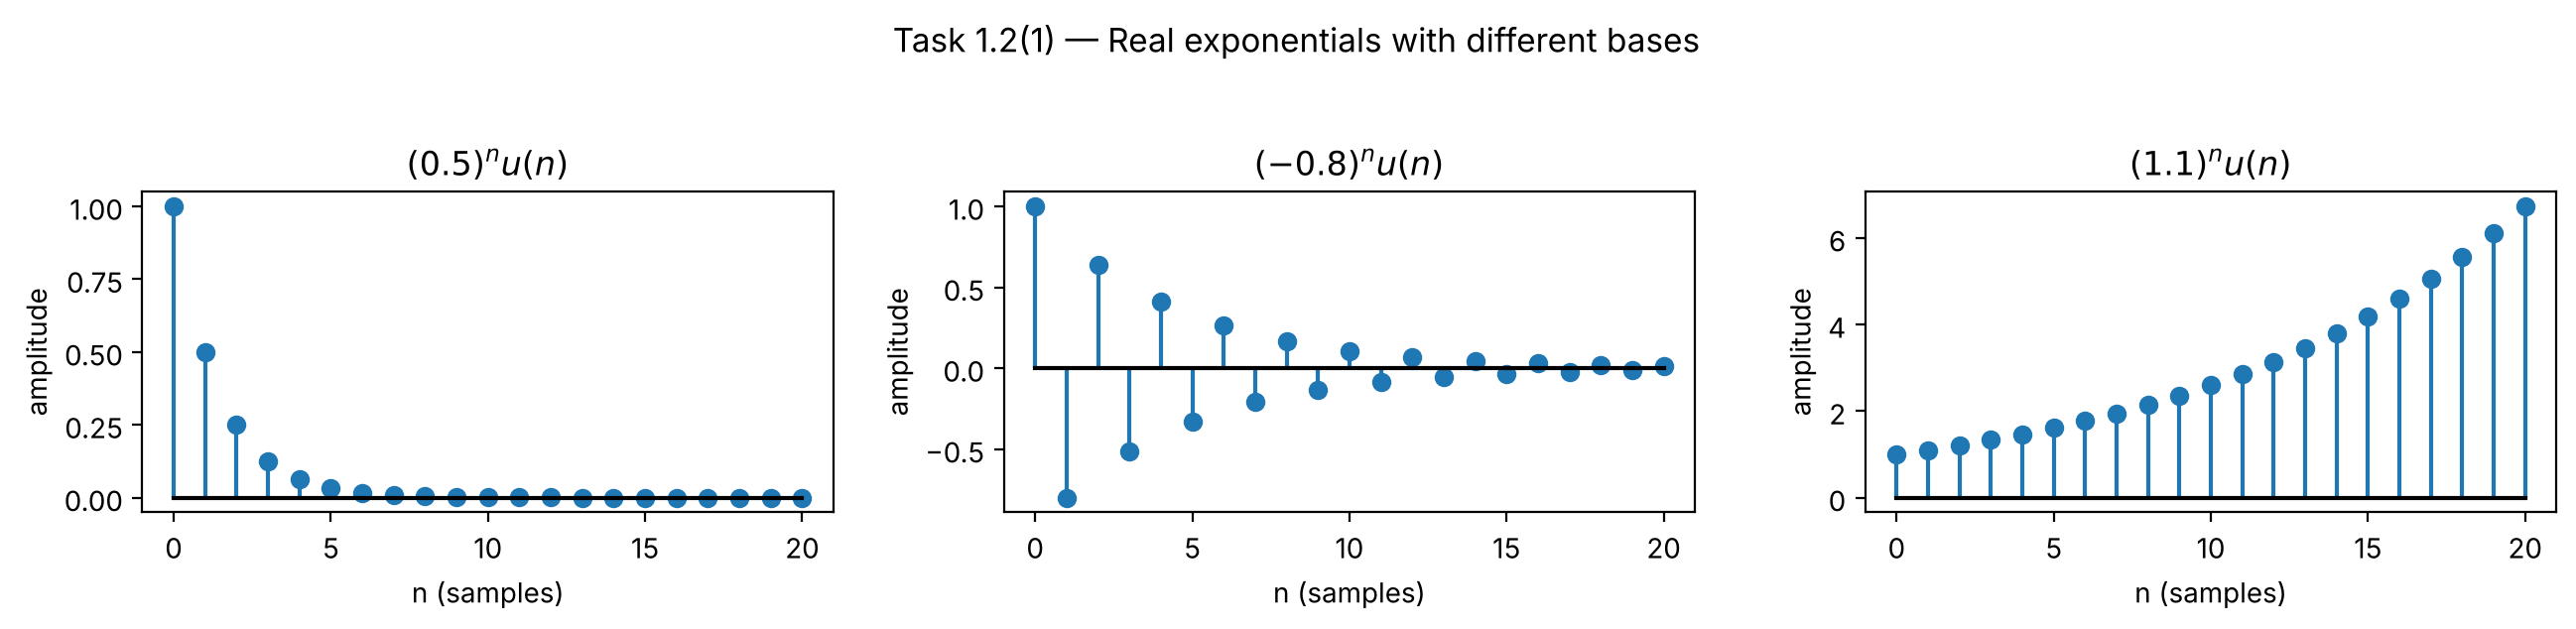

In [3]:
n = np.arange(0, 21)
u = (n >= 0).astype(float)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * u, basefmt="k-")
    ax.set_title(f"$({a})^n u(n)$"); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
fig.suptitle("Task 1.2(1) — Real exponentials with different bases", y=1.04)
plt.tight_layout(); plt.show()

**Observation.** For $a = 0.5$ the sequence decays quickly to zero. For $a = -0.8$ it alternates in sign
(+, −, +, …) while its magnitude decays. For $a = 1.1$ it grows without limit (about 6.7 at $n = 20$).

### 2. $\cos(2\pi n/8)$ and $\cos(2\pi n/7.5)$ for $0 \le n \le 40$

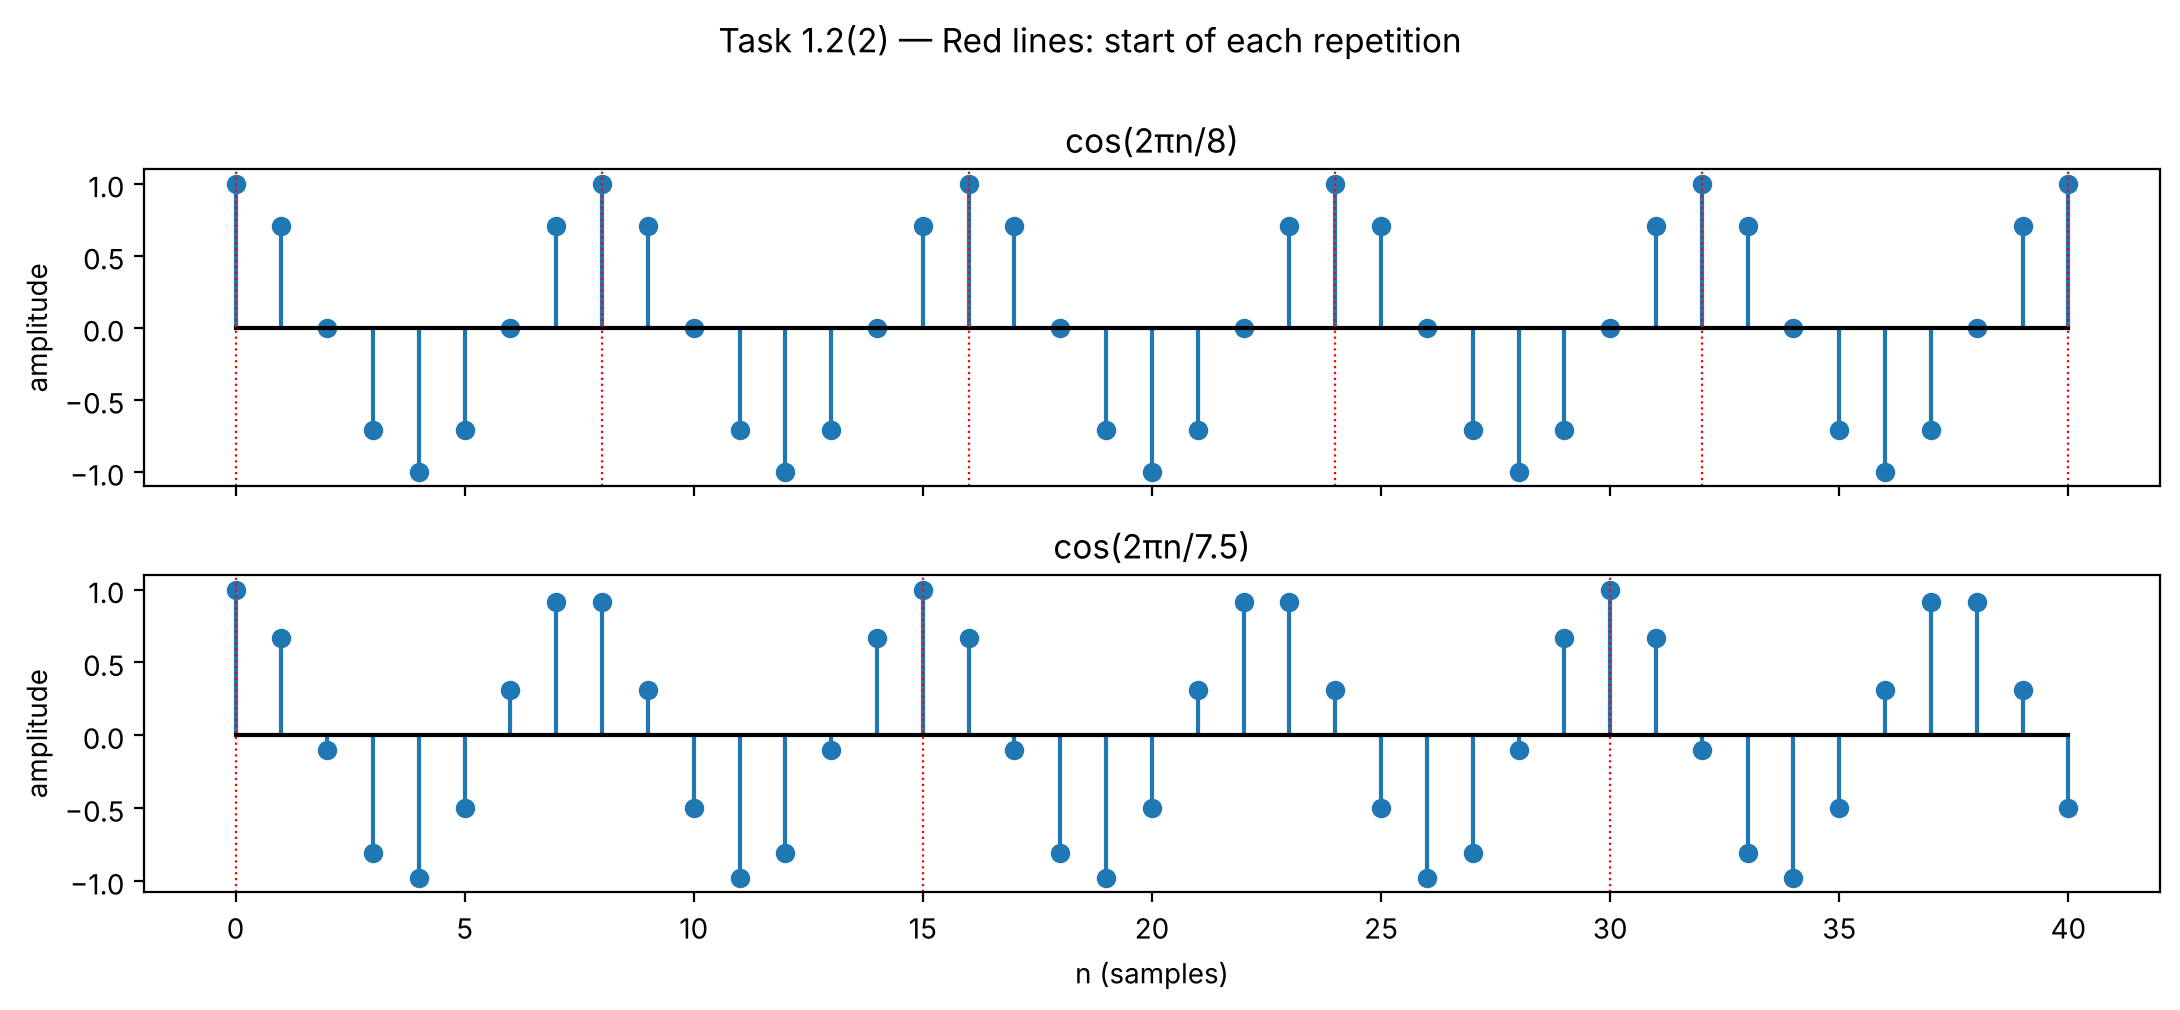

cos(2πn/8)     repeats after N= 8: True
cos(2πn/8)     repeats after N=15: False
cos(2πn/7.5)   repeats after N= 8: False
cos(2πn/7.5)   repeats after N=15: True


In [4]:
n = np.arange(0, 41)
x8 = np.cos(2*np.pi*n/8)
x75 = np.cos(2*np.pi*n/7.5)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].stem(n, x8, basefmt="k-"); axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, x75, basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for ax in axes:
    ax.set_ylabel("amplitude")
    for k in range(0, 41, 8 if ax is axes[0] else 15):
        ax.axvline(k, color="r", ls=":", lw=0.8)
axes[1].set_xlabel("n (samples)")
fig.suptitle("Task 1.2(2) — Red lines: start of each repetition", y=1.0)
plt.tight_layout(); plt.show()

# Numerical check: does the sequence repeat after N samples?
for name, x in [("cos(2πn/8)", x8), ("cos(2πn/7.5)", x75)]:
    for N in [8, 15]:
        print(f"{name:14s} repeats after N={N:2d}: {np.allclose(x[:41-N], x[N:])}")

**Which one repeats exactly?** $\cos(2\pi n/8)$ repeats exactly every 8 samples, the same as the analog
cosine's period. $\cos(2\pi n/7.5)$ does **not** repeat after 7.5 samples, because $n$ can only take
integer values and 7.5 is not an integer. It only repeats after **15** samples (two cycles of the analog
cosine). In general $\cos(2\pi f_0 n)$ is periodic only when $f_0 = k/N$ is a ratio of integers, and the
period is the smallest integer $N$ that works. This is explained further in Week 3.

## Task 1.3 — Working with audio
The code loads `my_voice.wav` (a 3–5 s phone recording placed in the same folder as this notebook). If
the file is missing, it uses a fallback test signal: a 440 Hz decaying tone.

source = my voice recording
fs = 48000 Hz, duration = 6.70 s, samples = 321536


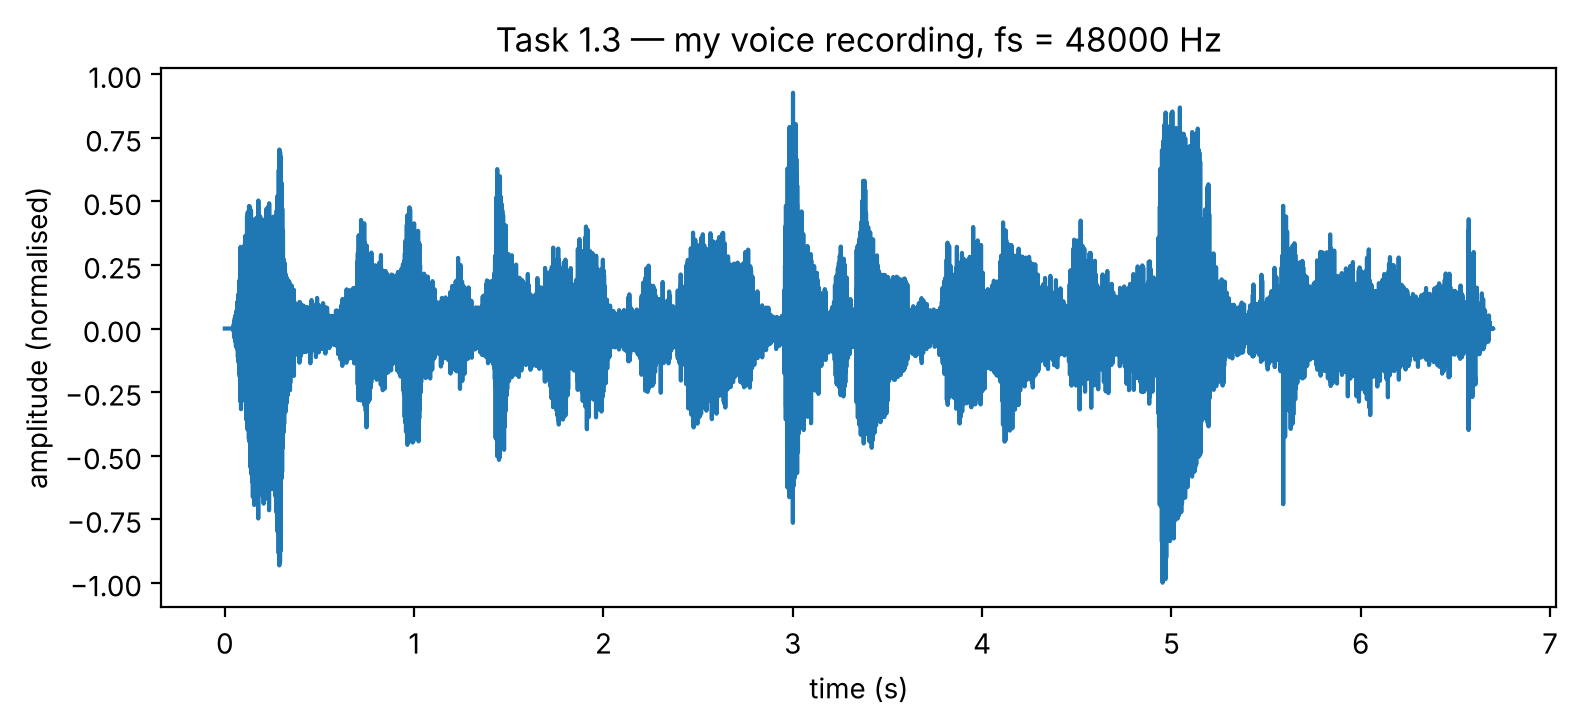

In [5]:
import os
fname = "my_voice.wav"                      # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                          # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))               # normalise to [-1, 1]
    source = "my voice recording"
else:                                       # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
    source = "fallback 440 Hz test signal"
t = np.arange(len(x)) / fs
print(f"source = {source}")
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x)
plt.xlabel("time (s)"); plt.ylabel("amplitude (normalised)")
plt.title(f"Task 1.3 — {source}, fs = {fs} Hz"); plt.show()

In [6]:
# Play back (headphones recommended)
Audio(x, rate=fs)

## Task 1.4 — The same in Octave (optional)
The Octave script `week01_task1_4.m` (in this folder) repeats Task 1.1. The cell below runs it if Octave
is installed and shows the saved figure.

**Syntax differences between Octave and Python/NumPy**

| Python / NumPy | Octave / MATLAB |
|---|---|
| `np.arange(-5, 11)` — end is excluded | `-5:10` — end is included |
| `(n >= 0).astype(float)` | `double(n >= 0)` |
| `x * y`, `a**n` (element-wise) | `x .* y`, `a .^ n` (the dot means element-wise) |
| indexing starts at 0, `x[0]` | indexing starts at 1, `x(1)` |
| `plt.subplots(1, 4)` | `subplot(1, 4, k)` |
| `import` needed | `pkg load signal` for signal functions |

Saved week01_octave_sequences.png


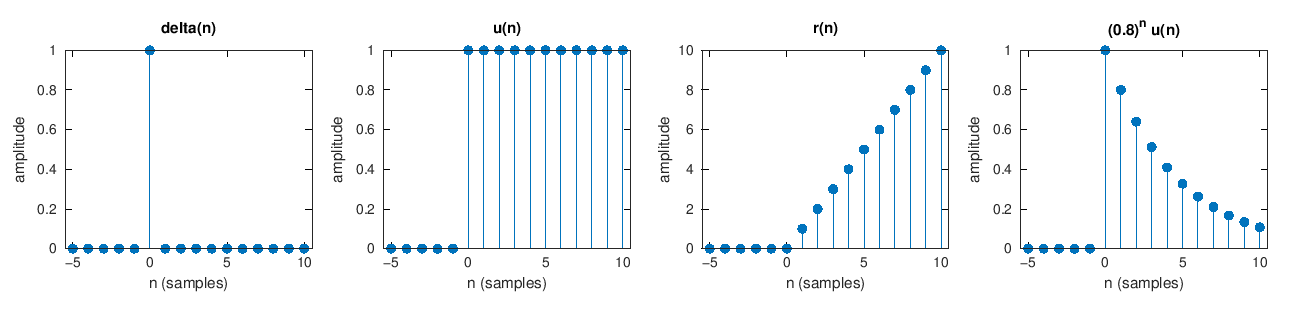

In [7]:
import shutil, subprocess
from IPython.display import Image
if shutil.which("octave"):
    out = subprocess.run(["octave", "--no-gui", "-q", "week01_task1_4.m"],
                         capture_output=True, text=True)
    print(out.stdout.strip())
    display(Image("week01_octave_sequences.png"))
else:
    print("Octave is not installed on this computer - run week01_task1_4.m in Octave instead.")

## Task 1.5 — Repository and submission
A Git repository holds all weekly notebooks:

```bash
cd DSP_LABS
git add Week01/
git commit -m "Week 1 - Lab 0 set-up notebook"
git remote add origin https://github.com/maimunahaji900-ship-it/DSP-LABS.git
git push -u origin main
```

**Repository link:** https://github.com/maimunahaji900-ship-it/DSP-LABS

The notebook `COU07506_Week01_250242423358.ipynb` is uploaded to DIT-eLMS.

**Checkpoint 1:** plots from Tasks 1.1–1.3 and the printed sampling rate and duration are shown above.

## Analysis questions

**1. What is the sampling rate of my phone's recording? How many numbers are needed to store one minute of it in mono?**

My recording (a phone voice note, converted to WAV) has $f_s$ = **48 000 Hz**, as printed in Task 1.3.
One minute in mono needs $f_s \times 60 = 48\,000 \times 60 =$ **2 880 000 numbers** (≈ 5.8 MB at 16 bits per
sample). The other common phone rate, 44.1 kHz, is shown for comparison:

In [8]:
for fs_phone in [44100, 48000]:
    N = fs_phone * 60
    print(f"fs = {fs_phone} Hz -> {N:,} samples per minute "
          f"= {N*2/1e6:.2f} MB at 16 bits per sample")

fs = 44100 Hz -> 2,646,000 samples per minute = 5.29 MB at 16 bits per sample
fs = 48000 Hz -> 2,880,000 samples per minute = 5.76 MB at 16 bits per sample


**2. Why is a stem plot more appropriate than a continuous line for $x(n)$?**

A discrete-time signal is only defined at integer values of $n$; between two samples it has no value.
A stem plot shows only the samples that exist. A continuous line joins the samples and suggests values
between them that do not exist in the signal.

**3. For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response?**

It would violate **BIBO stability** (§1.7). An LTI system is stable only if its impulse response is
absolutely summable, $\sum_n |h(n)| < \infty$. For $h(n) = (1.1)^n u(n)$ the sum grows without limit, so a
bounded input such as a unit step would give an output that grows without limit.

## Deliverables
- `COU07506_Week01_250242423358.ipynb` (this notebook) with Tasks 1.1–1.3, the pre-lab and the analysis answers
- Git repository link (above)
- Mini-project group: Group 30 (members listed at the top). Two possible topics are posted in the eLMS forum.

## AI-use statement
**Tool used:** Claude (Anthropic), a generative-AI assistant.

**What it was used for:** suggesting and explaining code for the tasks in this notebook and drafting
explanations, which I then reviewed and rewrote in my own words.

**How the results were checked:** the elementary sequences were compared with handout Figure 1.4; the periodicity claim in Task 1.2 was checked numerically with `np.allclose`; the sample-count arithmetic was recomputed in code.

I have run the notebook from top to bottom (Restart kernel → Run all) and I can explain every line of the code.